In [21]:
# prerequisites
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.autograd import Variable
from torchvision.utils import save_image

from VAE import VAE

In [22]:
import os
import pandas as pd
from torch.utils.data import Dataset, DataLoader

class CSVDataset(Dataset):
    def __init__(self, directory, transform=None):
        self.directory = directory
        self.transform = transform

        numerical = lambda _: int(''.join(filter(str.isdigit, _)))
        self.file_names = []
        for set in os.listdir(directory):
            csv_files = sorted((f for f in os.listdir(os.path.join(directory, set)) if f.endswith('.csv')), key = numerical)
            self.file_names.extend(list(map(lambda _:os.path.join(set, _), csv_files)))
        
        # self.file_names = [os.path.join(set, f)
        #                    for set in os.listdir(directory)
        #                    for f in os.listdir(os.path.join(directory, set)) if f.endswith('.csv')]

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_path = os.path.join(self.directory, self.file_names[idx])
        data = pd.read_csv(file_path, header=None, index_col=False).values
        data = data.astype('float32')
        
        if self.transform:
            data = self.transform(data)

        assert data.shape == (64, 32), f"Data shape mismatch: got {data.shape}, expected (64, 32)"

        return torch.tensor(data), 0

In [23]:
# Define transformations if any
transform = None

# Dataset directories
input_dir = './vae_input_mtruss'
train_directory = input_dir
test_directory = input_dir

# Create datasets
train_dataset = CSVDataset(directory=train_directory, transform=transform)
test_dataset = CSVDataset(directory=test_directory, transform=transform)

# Data Loader (Input Pipeline)
bs = 32
train_loader = DataLoader(dataset=train_dataset, batch_size=bs, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=bs, shuffle=False)

In [24]:
reconstructed_dir = './vae_output_mtruss/'
os.makedirs(reconstructed_dir, exist_ok=True)

In [25]:
"""
class VAE(nn.Module):
    def __init__(self, x_dim, h_dim1, h_dim2, z_dim):
        super(VAE, self).__init__()
        
        # encoder part
        self.fc1 = nn.Linear(x_dim, h_dim1)
        self.fc2 = nn.Linear(h_dim1, h_dim2)
        self.fc31 = nn.Linear(h_dim2, z_dim)
        self.fc32 = nn.Linear(h_dim2, z_dim)
        # decoder part
        self.fc4 = nn.Linear(z_dim, h_dim2)
        self.fc5 = nn.Linear(h_dim2, h_dim1)
        self.fc6 = nn.Linear(h_dim1, x_dim)
        
    def encoder(self, x):
        h = F.relu(self.fc1(x))
        h = F.relu(self.fc2(h))
        return self.fc31(h), self.fc32(h) # mu, log_var
    
    def sampling(self, mu, log_var):
        std = torch.exp(0.5*log_var)
        eps = torch.randn_like(std)
        return eps.mul(std).add_(mu) # return z sample
        
    def decoder(self, z):
        h = F.relu(self.fc4(z))
        h = F.relu(self.fc5(h))
        return F.sigmoid(self.fc6(h)) 
    
    def forward(self, x):
        mu, log_var = self.encoder(x.view(-1, 64*32))
        z = self.sampling(mu, log_var)
        return self.decoder(z), mu, log_var
"""

# build model
vae = VAE(x_dim=64*32, h_dim1= 512, h_dim2=256, z_dim=2)
if torch.cuda.is_available():
    vae.cuda()

In [26]:
vae

VAE(
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc31): Linear(in_features=256, out_features=2, bias=True)
  (fc32): Linear(in_features=256, out_features=2, bias=True)
  (fc4): Linear(in_features=2, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=512, bias=True)
  (fc6): Linear(in_features=512, out_features=2048, bias=True)
)

In [27]:
optimizer = optim.Adam(vae.parameters())
# return reconstruction error + KL divergence losses
def loss_function(recon_x, x, mu, log_var):
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 64*32), reduction='sum')
    KLD = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return BCE + KLD

In [28]:
def train(epoch):
    vae.train()
    train_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.cuda()
        optimizer.zero_grad()
        
        recon_batch, mu, log_var = vae(data)
        loss = loss_function(recon_batch, data, mu, log_var)
        
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
        
        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item() / len(data)))
    print('====> Epoch: {} Average loss: {:.4f}'.format(epoch, train_loss / len(train_loader.dataset)))

In [29]:
def test():
    vae.eval()
    test_loss= 0
    with torch.no_grad():
        for data, _ in test_loader:
            data = data.cuda()
            recon, mu, log_var = vae(data)
            
            # sum up batch loss
            test_loss += loss_function(recon, data, mu, log_var).item()
        
    test_loss /= len(test_loader.dataset)
    print('====> Test set loss: {:.4f}'.format(test_loss))

In [30]:
for epoch in range(1, 201):
    train(epoch)
    test()

Train Epoch: 1 [0/33 (0%)]	Loss: 1424.295654
====> Epoch: 1 Average loss: 1423.3121
====> Test set loss: 1333.2815
Train Epoch: 2 [0/33 (0%)]	Loss: 1333.074341
====> Epoch: 2 Average loss: 1329.6343
====> Test set loss: 1084.8258
Train Epoch: 3 [0/33 (0%)]	Loss: 1087.508423
====> Epoch: 3 Average loss: 1082.9630
====> Test set loss: 1041.2719
Train Epoch: 4 [0/33 (0%)]	Loss: 1043.729980
====> Epoch: 4 Average loss: 1038.0002
====> Test set loss: 857.5834
Train Epoch: 5 [0/33 (0%)]	Loss: 860.129883
====> Epoch: 5 Average loss: 857.2700
====> Test set loss: 812.9585
Train Epoch: 6 [0/33 (0%)]	Loss: 812.040466
====> Epoch: 6 Average loss: 811.0693
====> Test set loss: 810.3544
Train Epoch: 7 [0/33 (0%)]	Loss: 809.989380
====> Epoch: 7 Average loss: 812.3550
====> Test set loss: 793.7684
Train Epoch: 8 [0/33 (0%)]	Loss: 791.020996
====> Epoch: 8 Average loss: 794.0660
====> Test set loss: 779.9090
Train Epoch: 9 [0/33 (0%)]	Loss: 776.125854
====> Epoch: 9 Average loss: 780.2556
====> Test 

KeyboardInterrupt: 

In [31]:
with torch.no_grad():
    z = torch.randn(64, 2).cuda()
    sample = vae.decoder(z).cuda()
    
    save_image(sample.view(64, 1, 64, 32), os.path.join(reconstructed_dir, 'sample') + '.png')

In [32]:
# Create a grid of evenly spaced points around (0, 0)
n_points = 8  # Number of points along one dimension
grid_x = torch.linspace(-0.5, 0.5, n_points)
grid_y = torch.linspace(-0.5, 0.5, n_points)
grid = torch.cartesian_prod(grid_x, grid_y).cuda()

# Ensure the grid has the correct shape (64, 2)
z = grid.view(-1, 2)

with torch.no_grad():
    sample = vae.decoder(z).cuda()
    
    save_image(sample.view(64, 1, 64, 32), os.path.join(reconstructed_dir, 'sample_') + '.png')

In [33]:
input_loader = DataLoader(dataset=train_dataset, batch_size=1, shuffle=False)

66


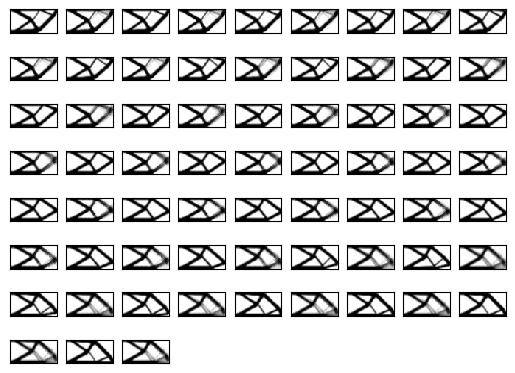

In [34]:
with torch.no_grad():
    for batch_idx, (data, _) in enumerate(input_loader):
        # Move data to GPU if available
        data = data.cuda()
        restored = vae.forward(data)[0]

        pd.DataFrame(data.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_data.csv', index=False, header=False)
        pd.DataFrame(restored.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_rest.csv', index=False, header=False)


        # save_image(data.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_data' + '.png')
        # save_image(restored.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_restored' + '.png')

from csv2fig import csv2fig
csv2fig(reconstructed_dir, reconstructed_dir, False)

In [35]:
# torch.save(vae.state_dict(), './vae_model_mtruss.pt')

In [36]:
load_model = VAE(x_dim=64*32, h_dim1= 512, h_dim2=256, z_dim=2)
load_model.load_state_dict(torch.load('./vae_model_mtruss.pt'))

C:\Users\User\AppData\Local\Temp\ipykernel_15356\3859169236.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  load_model.load_state_dict(torch.load('./vae_model_mtruss.pt'

<All keys matched successfully>

In [75]:
from FEA_Comp import fea_c
from bc_options import *

with torch.no_grad():
    z = torch.randn(1, 2)
    sample = load_model.decoder(z).cuda()
    
    z_ = torch.randn(1, 2)
    sample_ = load_model.decoder(z_).cuda()

n1 = pd.DataFrame(sample.cpu().view(64, 32)).to_numpy()
n2 = pd.DataFrame(sample_.cpu().view(64, 32)).to_numpy()

fea_c(64, 32, MTruss, 0, 2112, n1), fea_c(64, 32, MTruss, 0, 2112, n2)

(143.414420071973, 302.0808975538164)

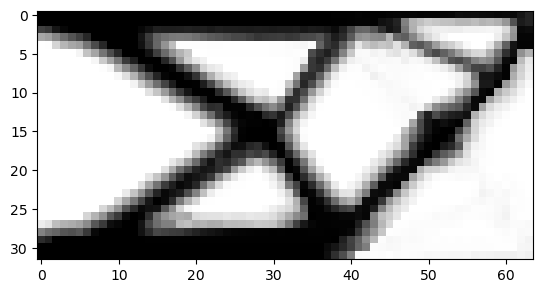

In [76]:
from matplotlib import colors
import matplotlib.pyplot as plt

_,ax = plt.subplots()
ax.imshow(-n1.reshape((64,32)).T, cmap='gray', interpolation='none', norm=colors.Normalize(vmin=-1,vmax=0))
plt.show()

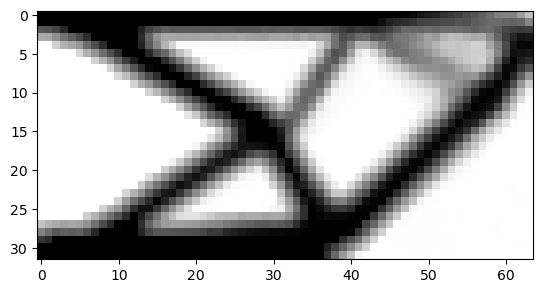

In [77]:
_,ax = plt.subplots()
ax.imshow(-n2.reshape((64,32)).T, cmap='gray', interpolation='none', norm=colors.Normalize(vmin=-1,vmax=0))
plt.show()

In [78]:
z, z_

(tensor([[ 1.4151, -1.4250]]), tensor([[ 1.3224, -0.2660]]))